In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Chargement des données 
df =pd.read_csv("Auto Sales data.csv")

In [3]:
#Préparation des données temporelles
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])

df["YEAR"] = df["ORDERDATE"].dt.year
df["MONTH"] = df["ORDERDATE"].dt.month
df["YEAR_MONTH"] = df["ORDERDATE"].dt.to_period("M")

C:\Users\DC\AppData\Local\Temp\ipykernel_13032\677211979.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])


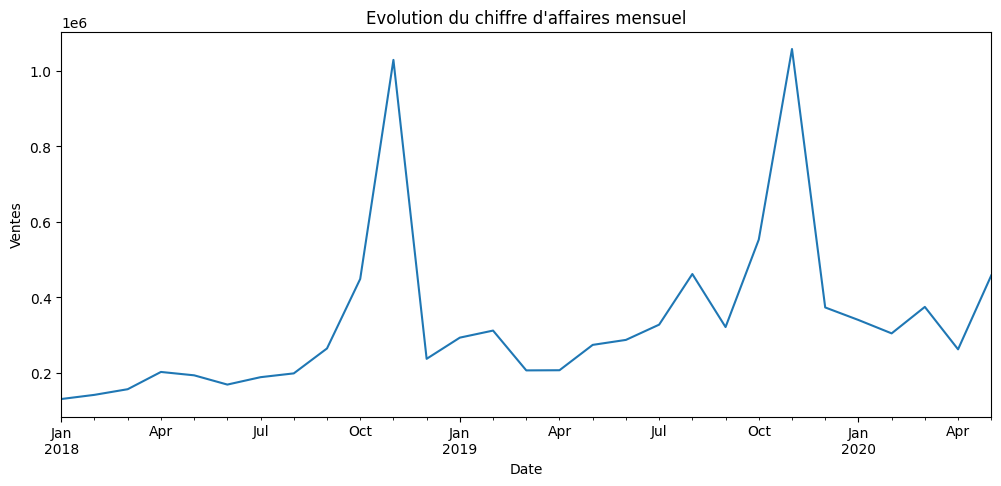

In [5]:
#Evolution du chiffre d'affaires dans le temps 
monthly_sales = df.groupby("YEAR_MONTH")["SALES"].sum()

monthly_sales.plot(figsize=(12,5))
plt.title("Evolution du chiffre d'affaires mensuel")
plt.xlabel("Date")
plt.ylabel("Ventes")
plt.show()

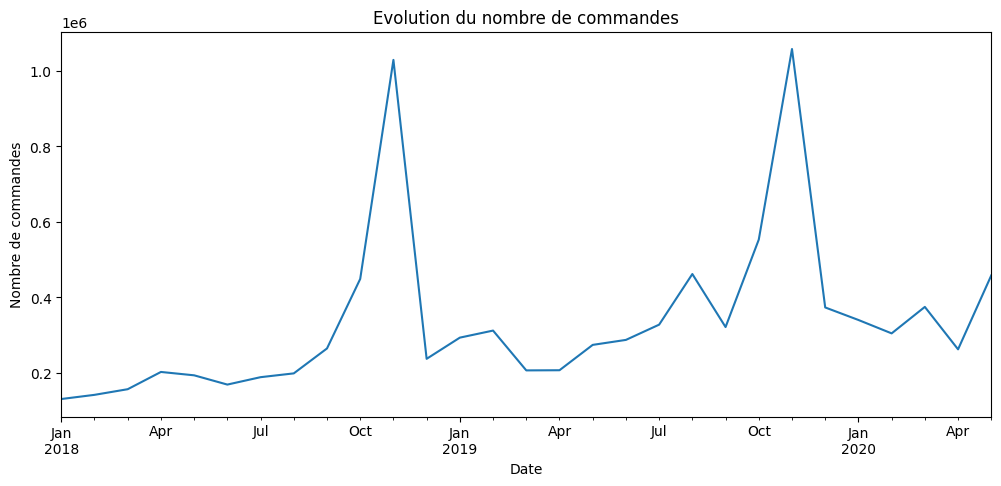

In [6]:
#Nombre de commandes dans le temps
monthly_orders = df.groupby("YEAR_MONTH")["ORDERNUMBER"].nunique()

monthly_sales.plot(figsize=(12,5))
plt.title("Evolution du nombre de commandes")
plt.xlabel("Date")
plt.ylabel("Nombre de commandes")
plt.show()

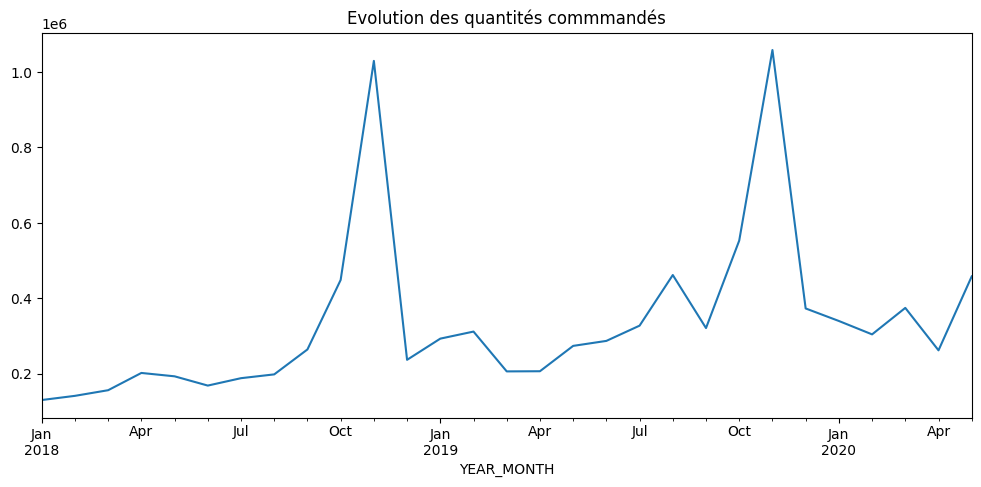

In [16]:
#Quantité vendue dans le temps
monthly_quantity = df.groupby("YEAR_MONTH")["QUANTITYORDERED"].sum()

monthly_sales.plot(figsize=(12,5))
plt.title("Evolution des quantités commmandés")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

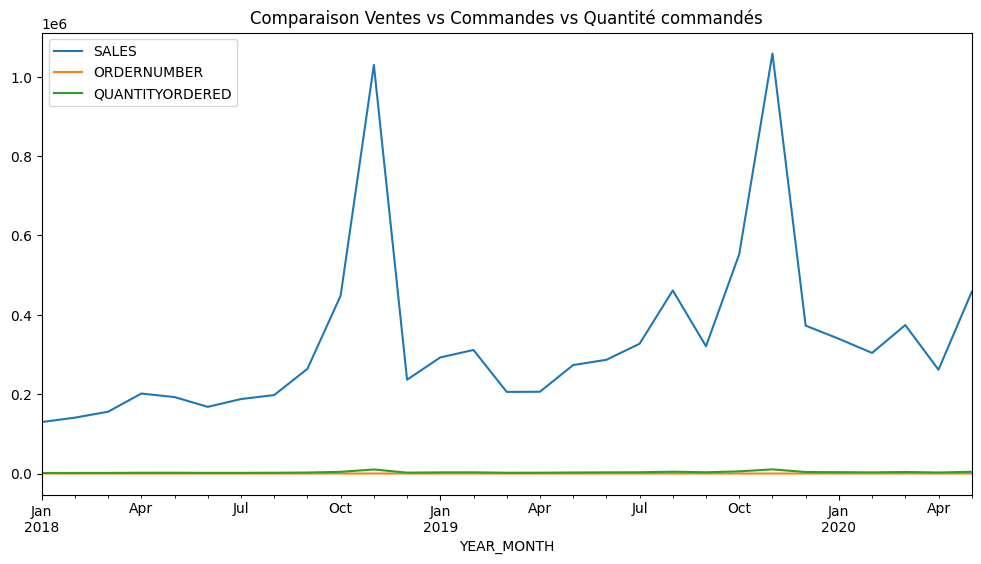

In [9]:
#Comparaison CA vs Commandes
time_analysis = df.groupby("YEAR_MONTH").agg({
    "SALES" : "sum",
    "ORDERNUMBER" : "nunique",
    "QUANTITYORDERED" : "sum"

})

time_analysis.plot(figsize=(12,6))
plt.title("Comparaison Ventes vs Commandes vs Quantité commandés")
plt.show

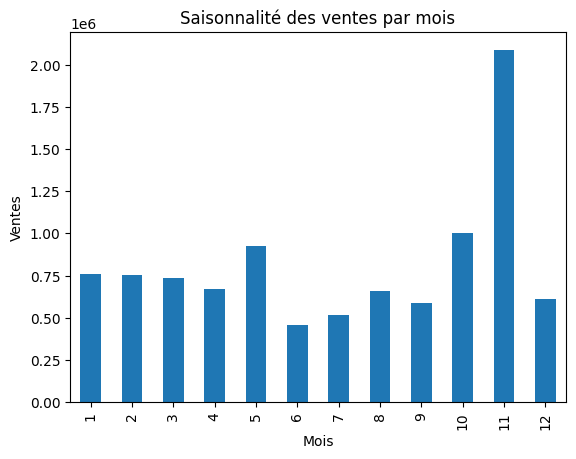

In [10]:
#Analyse saisonnière
Monthly_seasonality = df.groupby("MONTH")["SALES"].sum()

Monthly_seasonality.plot(kind="bar")
plt.title("Saisonnalité des ventes par mois")
plt.xlabel("Mois")
plt.ylabel("Ventes")
plt.show()

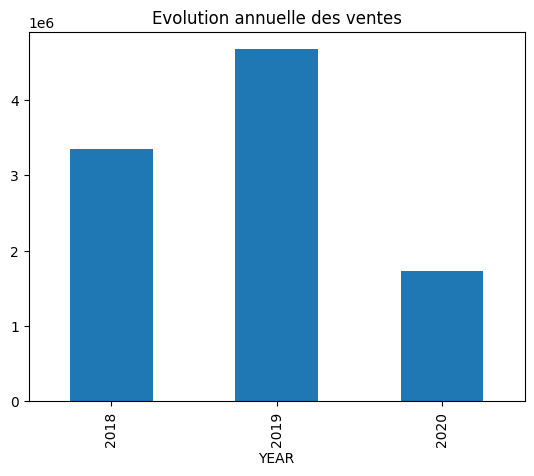

In [11]:
#Analyse annuelle
yearly_sales = df.groupby("YEAR")["SALES"].sum()

yearly_sales.plot(kind="bar")
plt.title("Evolution annuelle des ventes")
plt.show()

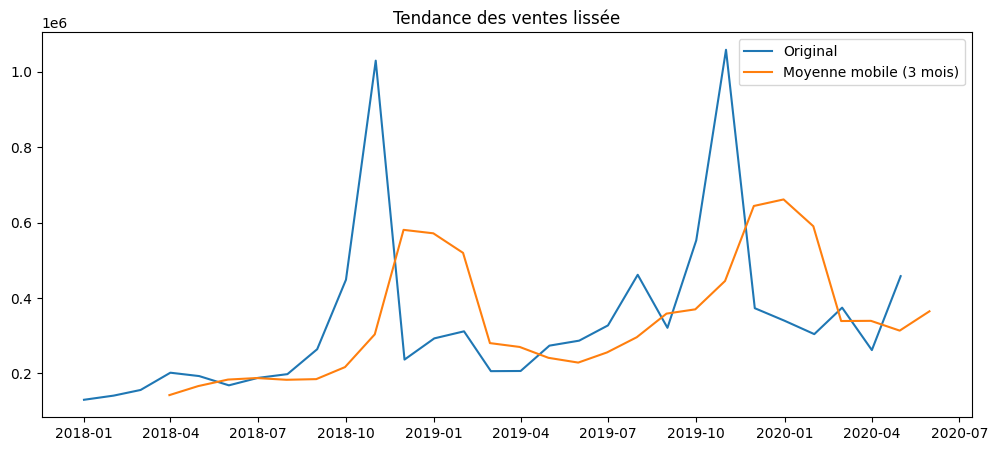

In [15]:
#Moyenne mobile
monthly_sales_ma = monthly_sales.rolling(window=3).mean()

monthly_sales.index = monthly_sales.index.to_timestamp()
plt.figure(figsize=(12,5))
plt.plot(monthly_sales, label="Original")
plt.plot(monthly_sales_ma, label="Moyenne mobile (3 mois)")
plt.legend()
plt.title("Tendance des ventes lissée")
plt.show()